# TASK-013 — Dataset Quality Audit
Checks the 8,000-article synthetic set, compares it with AG News, and reviews the TASK-009 filtered set. Figures and statistics are shown below.

In [1]:
from pathlib import Path
from collections import Counter
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data" / "synthetic" / "full_synthetic.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
from filter_data import CATEGORIES, _embed, _real_screening_pool, distinct_2, normalize, words

raw = pd.read_csv(ROOT / "data" / "synthetic" / "full_synthetic.csv")
clean = pd.read_csv(ROOT / "data" / "synthetic" / "full_filtered.csv")
stats = json.loads((ROOT / "results" / "full_filtering_stats.json").read_text(encoding="utf-8"))
assert len(raw) == 8_000
assert len(clean) + sum(stats["removed_counts"].values()) == len(raw)
assert set(clean.sample_id).issubset(set(raw.sample_id))
print("Unfiltered:", len(raw), "| Filtered:", len(clean))
print("Filter settings:", stats["settings"])

Unfiltered: 8000 | Filtered: 7427
Filter settings: {'min_words': 35, 'max_words': 80, 'near_duplicate_cosine_threshold': 0.95, 'embedding_model': 'all-minilm:latest', 'embedding_digest': '1b226e2802dbb772b5fc32a58f103ca1804ef7501331012de126ab22f67475ef', 'label_check_model': 'qwen3:4b-instruct', 'label_check_digest': '0edcdef34593eac1aa2be9c7d06c432dcf81945adca5eca2f27662c18f168ba0', 'label_check_mode': 'screen'}


In [2]:
def integrity(frame):
    text = frame.text.fillna("").astype(str)
    valid_label = frame.apply(
        lambda row: row.label in CATEGORIES and row.category == CATEGORIES.get(row.label),
        axis=1,
    )
    return {
        "rows": len(frame),
        "missing_text": int(frame.text.isna().sum()),
        "blank_text": int(text.str.strip().eq("").sum()),
        "missing_label": int(frame.label.isna().sum()),
        "invalid_label": int((~valid_label).sum()),
        "duplicate_ids": int(frame.sample_id.duplicated().sum()),
        "exact_duplicate_texts": int(text.map(normalize).duplicated().sum()),
        "length_outside_35_80": int((~text.map(lambda value: 35 <= len(words(value)) <= 80)).sum()),
    }

display(pd.DataFrame({"Unfiltered": integrity(raw), "Filtered": integrity(clean)}))
counts = pd.DataFrame({
    "Unfiltered": raw.category.value_counts(),
    "Filtered": clean.category.value_counts(),
}).reindex(CATEGORIES.values()).fillna(0).astype(int)
display(counts)
display(pd.DataFrame.from_dict(stats["removed_counts"], orient="index", columns=["removed"]))
print("Label screening:", stats.get("label_screen", {}))
print("Near-duplicate pairs (cosine >= 0.95):",
      stats["near_duplicate_pairs_before"], "before;",
      stats["near_duplicate_pairs_after"], "after")

,Unfiltered,Filtered
rows,8000,7427
missing_text,0,0
blank_text,0,0
missing_label,0,0
invalid_label,0,0
duplicate_ids,0,0
exact_duplicate_texts,0,0
length_outside_35_80,0,0


,Unfiltered,Filtered
category,,
World,2000,1824
Sports,2000,1827
Business,2000,1890
Sci/Tech,2000,1886


,removed
invalid,0
length_outlier,0
exact_duplicate,0
manual_exclusion,0
near_duplicate,234
potential_label_mismatch,223
user_realism_review,36
geographic_technical_review,80


Label screening: {'source': 'https://huggingface.co/datasets/fancyzhx/ag_news', 'real_train_rows': 800, 'real_heldout_macro_f1': 0.8441, 'disagreements_before_threshold': 1730, 'candidate_rule': 'all embedding label disagreements', 'qwen_checked_candidates': 1730, 'unchecked_disagreements': 0, 'unresolved_qwen_checks': 0}
Near-duplicate pairs (cosine >= 0.95): 766 before; 0 after


In [3]:
with requests.Session() as session:
    real_pool = _real_screening_pool(session)
real_pool["category"] = real_pool.label.map(CATEGORIES)
assert len(real_pool) == 800 and real_pool.text.notna().all()
print("Real AG News screening pool:", len(real_pool))
display(real_pool.category.value_counts().reindex(CATEGORIES.values()).rename("AG News"))

n_each = min(100, int(real_pool.label.value_counts().min()),
             int(clean.label.value_counts().min()))
raw_match = raw.groupby("label", group_keys=False).sample(n=n_each, random_state=42)
clean_match = clean.groupby("label", group_keys=False).sample(n=n_each, random_state=42)
real_match = real_pool.groupby("label", group_keys=False).sample(n=n_each, random_state=42)
matched = {"Synthetic": raw_match, "Filtered": clean_match, "AG News": real_match}
print("Matched comparison:", n_each, "articles per category and source")
print("Exact synthetic/AG News text overlaps:",
      len(set(raw.text.map(normalize)) & set(real_pool.text.map(normalize))))

Real AG News screening pool: 800


category
World       135
Sports      168
Business    258
Sci/Tech    239
Name: AG News, dtype: int64

Matched comparison: 100 articles per category and source
Exact synthetic/AG News text overlaps: 0


In [4]:
length_rows = []
lexical_rows = []
for source, frame in matched.items():
    for category in CATEGORIES.values():
        group = frame[frame.category == category]
        lengths = group.text.map(lambda text: len(words(text)))
        length_rows.append({
            "source": source, "category": category, "n": len(group),
            "mean_words": lengths.mean(), "median_words": lengths.median(),
            "p95_words": lengths.quantile(0.95),
        })
        lexical_rows.append({
            "source": source, "category": category,
            "distinct_2_first35": distinct_2(group.text.tolist()),
        })
lengths = pd.DataFrame(length_rows)
lexical = pd.DataFrame(lexical_rows)
display(lengths.round(2))
display(lexical.pivot(index="category", columns="source",
                      values="distinct_2_first35").reindex(CATEGORIES.values()).round(3))

def content_words(frame):
    return Counter(
        word for text in frame.text for word in words(text)
        if len(word) > 2 and word not in ENGLISH_STOP_WORDS
    )
frequencies = {source: content_words(frame) for source, frame in matched.items()}
top_terms = list(dict.fromkeys(
    word for source in ("Synthetic", "AG News")
    for word, _ in frequencies[source].most_common(10)
))
distribution = pd.DataFrame({
    source: [frequencies[source][word] / sum(frequencies[source].values())
             for word in top_terms]
    for source in matched
}, index=top_terms)
display(distribution.round(4))

,source,category,n,mean_words,median_words,p95_words
0,Synthetic,World,100,67.45,68.0,77.05
1,Synthetic,Sports,100,67.50,69.0,77.10
2,Synthetic,Business,100,67.54,68.0,76.00
3,Synthetic,Sci/Tech,100,69.00,70.0,78.00
4,Filtered,World,100,68.51,69.0,79.00
5,Filtered,Sports,100,67.72,68.0,77.05
6,Filtered,Business,100,66.74,66.5,77.00
7,Filtered,Sci/Tech,100,70.36,71.0,79.00
8,AG News,World,100,38.38,37.5,53.10
9,AG News,Sports,100,37.71,37.0,51.10


source,AG News,Filtered,Synthetic
category,,,
World,0.863,0.730,0.747
Sports,0.865,0.728,0.705
Business,0.857,0.733,0.733
Sci/Tech,0.882,0.713,0.711


,Synthetic,Filtered,AG News
regional,0.0100,0.0107,0.0003
local,0.0092,0.0098,0.0002
new,0.0078,0.0090,0.0081
data,0.0068,0.0069,0.0009
rural,0.0061,0.0046,0.0000
amid,0.0054,0.0056,0.0003
initiative,0.0052,0.0044,0.0001
aims,0.0050,0.0038,0.0003
revised,0.0047,0.0046,0.0000
time,0.0046,0.0046,0.0019


In [5]:
with requests.Session() as session:
    all_vectors = _embed(session, raw.text.tolist() + real_pool.text.tolist())
raw_vectors = all_vectors[:len(raw)]
real_vectors = all_vectors[len(raw):]
raw_positions = dict(zip(raw.sample_id, range(len(raw))))
real_positions = dict(zip(real_pool.row_idx, range(len(real_pool))))

def semantic_diversity(vectors):
    similarity = vectors @ vectors.T
    upper = similarity[np.triu_indices(len(vectors), k=1)]
    return float(1 - upper.mean()), int((upper >= 0.90).sum())

full_semantic_rows = []
for source, frame in (("Synthetic", raw), ("Filtered", clean)):
    for category in CATEGORIES.values():
        group = frame[frame.category == category]
        positions = [raw_positions[sid] for sid in group.sample_id]
        score, near_pairs = semantic_diversity(raw_vectors[positions])
        full_semantic_rows.append({
            "source": source, "category": category, "n": len(group),
            "semantic_diversity": score, "pairs_cosine_ge_0_90": near_pairs,
        })
full_semantic = pd.DataFrame(full_semantic_rows)
display(full_semantic.round(3))

matched_semantic_rows = []
for source, frame in matched.items():
    for category in CATEGORIES.values():
        group = frame[frame.category == category]
        vectors = (real_vectors[[real_positions[idx] for idx in group.row_idx]]
                   if source == "AG News"
                   else raw_vectors[[raw_positions[sid] for sid in group.sample_id]])
        score, near_pairs = semantic_diversity(vectors)
        matched_semantic_rows.append({
            "source": source, "category": category, "n": len(group),
            "semantic_diversity": score,
            "pairs_cosine_ge_0_90": near_pairs,
        })
matched_semantic = pd.DataFrame(matched_semantic_rows)
display(matched_semantic.round(3))

Embedded 2000/8800 texts


Embedded 4000/8800 texts


Embedded 6000/8800 texts


Embedded 8000/8800 texts


,source,category,n,semantic_diversity,pairs_cosine_ge_0_90
0,Synthetic,World,2000,0.793,166
1,Synthetic,Sports,2000,0.780,1560
2,Synthetic,Business,2000,0.776,1028
3,Synthetic,Sci/Tech,2000,0.774,516
4,Filtered,World,1824,0.791,48
5,Filtered,Sports,1827,0.769,191
6,Filtered,Business,1890,0.775,127
7,Filtered,Sci/Tech,1886,0.773,146


,source,category,n,semantic_diversity,pairs_cosine_ge_0_90
0,Synthetic,World,100,0.792,0
1,Synthetic,Sports,100,0.781,6
2,Synthetic,Business,100,0.776,1
3,Synthetic,Sci/Tech,100,0.782,0
4,Filtered,World,100,0.785,1
5,Filtered,Sports,100,0.770,0
6,Filtered,Business,100,0.781,1
7,Filtered,Sci/Tech,100,0.773,0
8,AG News,World,100,0.912,2
9,AG News,Sports,100,0.873,1


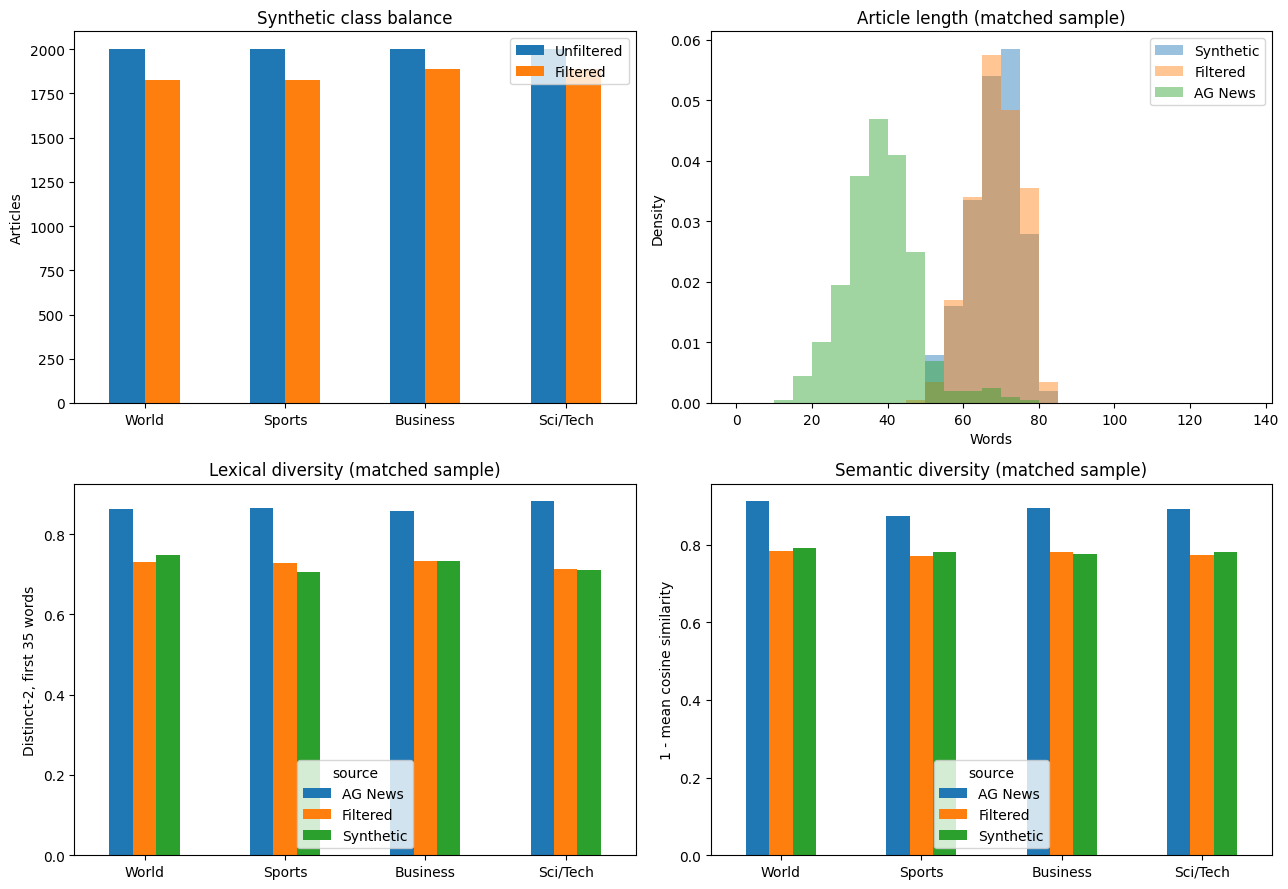

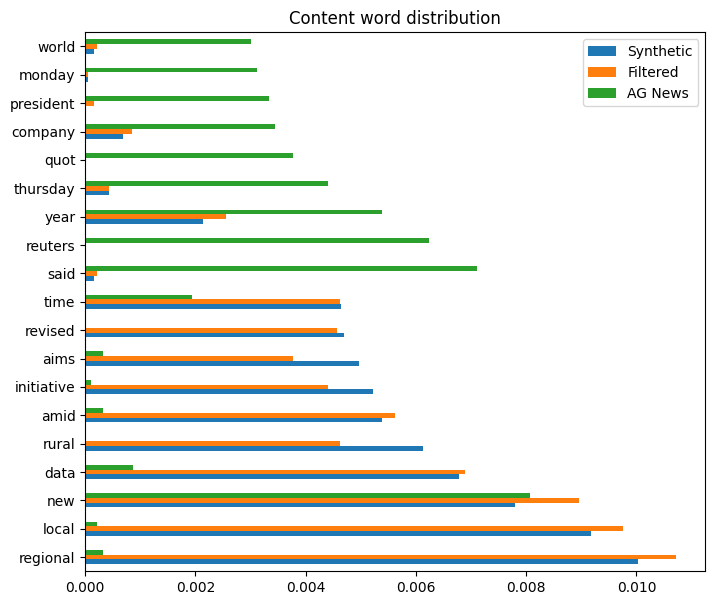

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
counts.plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Synthetic class balance", xlabel="", ylabel="Articles")
for source, frame in matched.items():
    axes[0, 1].hist(frame.text.map(lambda text: len(words(text))),
                    bins=np.arange(0, 140, 5), density=True, alpha=0.45, label=source)
axes[0, 1].set(title="Article length (matched sample)", xlabel="Words", ylabel="Density")
axes[0, 1].legend()
lexical.pivot(index="category", columns="source",
              values="distinct_2_first35").reindex(CATEGORIES.values()).plot.bar(
                  ax=axes[1, 0], rot=0)
axes[1, 0].set(title="Lexical diversity (matched sample)",
               xlabel="", ylabel="Distinct-2, first 35 words")
matched_semantic.pivot(index="category", columns="source",
                       values="semantic_diversity").reindex(CATEGORIES.values()).plot.bar(
                           ax=axes[1, 1], rot=0)
axes[1, 1].set(title="Semantic diversity (matched sample)",
               xlabel="", ylabel="1 - mean cosine similarity")
fig.tight_layout()
plt.show()

display(distribution.plot.barh(figsize=(8, 7), title="Content word distribution").figure)
plt.close("all")

In [7]:
final = pd.read_csv(ROOT / "data" / "synthetic" / "final_8000.csv")
assert len(final) == 8_000 and final.sample_id.is_unique
assert final.category.value_counts().to_dict() == {name: 2_000 for name in CATEGORIES.values()}
assert not final.text.map(normalize).duplicated().any()
display(final.category.value_counts().reindex(CATEGORIES.values()).rename("Final articles"))
print("Selected replacements:", stats["finalization"]["selected_by_category"])
print("Replacement removals:", stats["finalization"]["replacement_removed_counts"])


category
World       2000
Sports      2000
Business    2000
Sci/Tech    2000
Name: Final articles, dtype: int64

Selected replacements: {'World': 176, 'Sports': 173, 'Business': 110, 'Sci/Tech': 114}
Replacement removals: {'invalid': 0, 'inconsistency': 3, 'exact_duplicate': 0, 'near_duplicate_base': 2, 'near_duplicate_replacement': 8, 'potential_label_mismatch': 32, 'unresolved_label_check': 0, 'consistency_review': 32, 'unresolved_consistency_review': 2}


Label checks use an AG News embedding classifier to screen for possible mismatches and Qwen3-4B to confirm selected cases. This audit does not establish factual accuracy for every generated article.